Lets begin by adding and loading all the packages that will be useful along the notebook.

In [1]:
using Pkg
# Ensure required packages (uncomment to install if needed)
Pkg.add([
    "MLJ", 
    "MLJBase", 
    "MLJModels", 
    "MLJEnsembles", 
    "MLJLinearModels", 
    "DecisionTree", 
    "MLJDecisionTreeInterface",
    "NaiveBayes",
    "MLJNaiveBayesInterface", 
    "EvoTrees", 
    "CategoricalArrays", 
    "Random",
    "LIBSVM",           
    "MLJLIBSVMInterface", 
    "Plots",
    "MLJModelInterface",
    "CSV",       
    "DataFrames",      
    "UrlDownload",
    "XGBoost"    
])

   Resolving package versions...
  No Changes to `~/.julia/environments/v1.9/Project.toml`
  No Changes to `~/.julia/environments/v1.9/Manifest.toml`


In [ ]:
using Pkg;
Pkg.add("CSV")
Pkg.add("DataFrames")

using DataFrames;
using CSV;
using CategoricalArrays;
using Random;

   Resolving package versions...
  No Changes to `~/.julia/environments/v1.9/Project.toml`
  No Changes to `~/.julia/environments/v1.9/Manifest.toml`
   Resolving package versions...
  No Changes to `~/.julia/environments/v1.9/Project.toml`
  No Changes to `~/.julia/environments/v1.9/Manifest.toml`


In [139]:
include("work/functions.jl") # All previously defined functions

   Resolving package versions...
  No Changes to `~/.julia/environments/v1.9/Project.toml`
  No Changes to `~/.julia/environments/v1.9/Manifest.toml`


import MLJLIBSVMInterface ✔


[ Info: For silent loading, specify `verbosity=0`. 
   Resolving package versions...
  No Changes to `~/.julia/environments/v1.9/Project.toml`
  No Changes to `~/.julia/environments/v1.9/Manifest.toml`
   Resolving package versions...
  No Changes to `~/.julia/environments/v1.9/Project.toml`
  No Changes to `~/.julia/environments/v1.9/Manifest.toml`


bin_to_multiclass (generic function with 1 method)

In [ ]:


Random.seed!(1234);
df = CSV.read("data/communities.data", DataFrame; header=false, missingstring="?");
df

Row,Column1,Column2,Column3,Column4,Column5,Column6,Column7,Column8,Column9,Column10,Column11,Column12,Column13,Column14,Column15,Column16,Column17,Column18,Column19,Column20,Column21,Column22,Column23,Column24,Column25,Column26,Column27,Column28,Column29,Column30,Column31,Column32,Column33,Column34,Column35,Column36,Column37,Column38,Column39,Column40,Column41,Column42,Column43,Column44,Column45,Column46,Column47,Column48,Column49,Column50,Column51,Column52,Column53,Column54,Column55,Column56,Column57,Column58,Column59,Column60,Column61,Column62,Column63,Column64,Column65,Column66,Column67,Column68,Column69,Column70,Column71,Column72,Column73,Column74,Column75,Column76,Column77,Column78,Column79,Column80,Column81,Column82,Column83,Column84,Column85,Column86,Column87,Column88,Column89,Column90,Column91,Column92,Column93,Column94,Column95,Column96,Column97,Column98,Column99,Column100,⋯
,Int64,Int64?,Int64?,String31,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64?,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,⋯
1,8,missing,missing,Lakewoodcity,1,0.19,0.33,0.02,0.9,0.12,0.17,0.34,0.47,0.29,0.32,0.2,1.0,0.37,0.72,0.34,0.6,0.29,0.15,0.43,0.39,0.4,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.1,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.4,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.04,0.14,0.03,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.5,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.04,0.0,0.12,0.42,0.5,0.51,⋯
2,53,missing,missing,Tukwilacity,1,0.0,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.3,0.22,0.35,0.01,0.24,0.14,0.24,0.3,0.27,0.73,0.57,0.15,0.42,0.36,1.0,0.63,0.91,1.0,0.29,0.43,0.47,0.6,0.39,0.46,0.53,0.0,0.24,0.01,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.1,0.16,0.1,0.17,0.29,0.17,0.26,0.2,0.82,0.0,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.0,0.21,0.2,0.21,0.42,0.38,0.4,0.37,0.29,0.32,0.18,0.0,0.0,0.21,0.5,0.34,0.6,⋯
3,24,missing,missing,Aberdeentown,1,0.0,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.0,0.0,0.3,0.58,0.19,0.39,0.38,0.4,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.7,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.01,0.46,0.0,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.2,0.2,0.46,0.52,0.43,0.42,0.15,0.51,0.5,0.01,0.86,0.41,0.29,0.3,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.0,0.0,0.14,0.49,0.54,0.67,⋯
4,34,5,81440,Willingborotownship,1,0.04,0.77,1.0,0.08,0.12,0.1,0.51,0.5,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.2,0.82,0.51,0.36,0.4,0.39,0.16,0.25,0.36,0.44,0.01,0.1,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.03,0.33,0.02,0.11,0.2,0.3,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.0,0.94,0.12,0.01,0.5,0.01,0.97,0.96,0.6,0.47,0.52,0.11,0.11,0.24,0.21,0.19,0.75,0.7,0.77,0.89,0.63,0.51,0.47,0.0,0.0,0.19,0.3,0.73,0.64,⋯
5,42,95,6096,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,0.02,0.9,0.5,0.72,0.16,0.68,0.44,0.11,0.71,0.46,0.43,0.41,0.28,0.0,0.74,0.51,0.48,0.0,0.06,0.25,0.3,0.33,0.12,0.65,0.67,0.38,0.42,0.46,0.22,0.27,0.2,0.21,0.51,0.91,0.91,0.89,0.85,0.4,0.6,0.0,0.06,0.0,0.03,0.07,0.2,0.27,0.01,0.02,

In [77]:
describe(df)

Row,variable,mean,min,median,max,nmissing,eltype
,Symbol,Union…,Any,Union…,Any,Int64,Type
1,Column1,28.6836,1,34.0,56,0,Int64
2,Column2,58.8268,1,23.0,840,1174,"Union{Missing, Int64}"
3,Column3,46188.3,70,48090.0,94597,1177,"Union{Missing, Int64}"
4,Column4,,Aberdeencity,,Zanesvillecity,0,String31
5,Column5,5.49398,1,5.0,10,0,Int64
6,Column6,0.0575928,0.0,0.02,1.0,0,Float64
7,Column7,0.463395,0.0,0.44,1.0,0,Float64
8,Column8,0.179629,0.0,0.06,1.0,0,Float64
9,Column9,0.753716,0.0,0.85,1.0,0,Float64


In [78]:
header_string = "state, county, community, communityname, fold, population, householdsize, racepctblack, racePctWhite, racePctAsian, racePctHisp, agePct12t21, agePct12t29, agePct16t24, agePct65up, numbUrban, pctUrban, medIncome, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, medFamInc, perCapInc, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, NumUnderPov, PctPopUnderPov, PctLess9thGrade, PctNotHSGrad, PctBSorMore, PctUnemployed, PctEmploy, PctEmplManu, PctEmplProfServ, PctOccupManu, PctOccupMgmtProf, MalePctDivorce, MalePctNevMarr, FemalePctDiv, TotalPctDiv, PersPerFam, PctFam2Par, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMomYoungKids, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec5, PctImmigRec8, PctImmigRec10, PctRecentImmig, PctRecImmig5, PctRecImmig8, PctRecImmig10, PctSpeakEnglOnly, PctNotSpeakEnglWell, PctLargHouseFam, PctLargHouseOccup, PersPerOccupHous, PersPerOwnOccHous, PersPerRentOccHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctHousOwnOcc, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, OwnOccMedVal, OwnOccHiQuart, RentLowQ, RentMedian, RentHighQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctBornSameState, PctSameHouse85, PctSameCity85, PctSameState85, LemasSwornFT, LemasSwFTPerPop, LemasSwFTFieldOps, LemasSwFTFieldPerPop, LemasTotalReq, LemasTotReqPerPop, PolicReqPerOffic, PolicPerPop, RacialMatchCommPol, PctPolicWhite, PctPolicBlack, PctPolicHisp, PctPolicAsian, PctPolicMinor, OfficAssgnDrugUnits, NumKindsDrugsSeiz, PolicAveOTWorked, LandArea, PopDens, PctUsePubTrans, PolicCars, PolicOperBudg, LemasPctPolicOnPatr, LemasGangUnitDeploy, LemasPctOfficDrugUn, PolicBudgPerPop, ViolentCrimesPerPop"
new_headers = [Symbol(strip(name)) for name in split(header_string, ',')]
rename!(df, Dict(names(df) .=> new_headers))

Row,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,perCapInc,whitePerCap,blackPerCap,indianPerCap,AsianPerCap,OtherPerCap,HispPerCap,NumUnderPov,PctPopUnderPov,PctLess9thGrade,PctNotHSGrad,PctBSorMore,PctUnemployed,PctEmploy,PctEmplManu,PctEmplProfServ,PctOccupManu,PctOccupMgmtProf,MalePctDivorce,MalePctNevMarr,FemalePctDiv,TotalPctDiv,PersPerFam,PctFam2Par,PctKids2Par,PctYoungKids2Par,PctTeen2Par,PctWorkMomYoungKids,PctWorkMom,NumIlleg,PctIlleg,NumImmig,PctImmigRecent,PctImmigRec5,PctImmigRec8,PctImmigRec10,PctRecentImmig,PctRecImmig5,PctRecImmig8,PctRecImmig10,PctSpeakEnglOnly,PctNotSpeakEnglWell,PctLargHouseFam,PctLargHouseOccup,PersPerOccupHous,PersPerOwnOccHous,PersPerRentOccHous,PctPersOwnOccup,PctPersDenseHous,PctHousLess3BR,MedNumBR,HousVacant,PctHousOccup,PctHousOwnOcc,PctVacantBoarded,PctVacMore6Mos,MedYrHousBuilt,PctHousNoPhone,PctWOFullPlumb,OwnOccLowQuart,OwnOccMedVal,OwnOccHiQuart,RentLowQ,RentMedian,RentHighQ,MedRent,MedRentPctHousInc,MedOwnCostPctInc,MedOwnCostPctIncNoMtg,NumInShelters,NumStreet,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,⋯
,Int64,Int64?,Int64?,String31,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64?,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,⋯
1,8,missing,missing,Lakewoodcity,1,0.19,0.33,0.02,0.9,0.12,0.17,0.34,0.47,0.29,0.32,0.2,1.0,0.37,0.72,0.34,0.6,0.29,0.15,0.43,0.39,0.4,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.1,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.4,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.04,0.14,0.03,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.5,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.04,0.0,0.12,0.42,0.5,0.51,⋯
2,53,missing,missing,Tukwilacity,1,0.0,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.3,0.22,0.35,0.01,0.24,0.14,0.24,0.3,0.27,0.73,0.57,0.15,0.42,0.36,1.0,0.63,0.91,1.0,0.29,0.43,0.47,0.6,0.39,0.46,0.53,0.0,0.24,0.01,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.1,0.16,0.1,0.17,0.29,0.17,0.26,0.2,0.82,0.0,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.0,0.21,0.2,0.21,0.42,0.38,0.4,0.37,0.29,0.32,0.18,0.0,0.0,0.21,0.5,0.34,0.6,⋯
3,24,missing,missing,Aberdeentown,1,0.0,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.0,0.0,0.3,0.58,0.19,0.39,0.38,0.4,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.7,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.01,0.46,0.0,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.2,0.2,0.46,0.52,0.43,0.42,0.15,0.51,0.5,0.01,0.86,0.41,0.29,0.3,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.0,0.0,0.14,0.49,0.54,0.67,⋯
4,34,5,81440,Willingborotownship,1,0.04,0.77,1.0,0.08,0.12,0.1,0.51,0.5,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.2,0.82,0.51,0.36,0.4,0.39,0.16,0.25,0.36,0.44,0.01,0.1,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.03,0.33,0.02,0.11,0.2,0.3,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.0,0.94,0.12,0.01,0.5,0.01,0.97,0.9

In [79]:
# coalesce.(x, 0) REPLACE MISSING WITH 0
n = 1675

# --- Core Logic ---

# 2. Count the missing values for each column
missing_counts = map(col -> sum(ismissing, col), eachcol(df))
# Result: [1, 3, 0, 5, 1]

# 3. Find the indices where the count equals n
column_indices = findall(==(n), missing_counts)
# Result: [2] (Index for column B)

# 4. Get the column names using the indices
columns_with_n_missings = names(df)[column_indices]

22-element Vector{String}:
 "LemasSwornFT"
 "LemasSwFTPerPop"
 "LemasSwFTFieldOps"
 "LemasSwFTFieldPerPop"
 "LemasTotalReq"
 "LemasTotReqPerPop"
 "PolicReqPerOffic"
 "PolicPerPop"
 "RacialMatchCommPol"
 "PctPolicWhite"
 "PctPolicBlack"
 "PctPolicHisp"
 "PctPolicAsian"
 "PctPolicMinor"
 "OfficAssgnDrugUnits"
 "NumKindsDrugsSeiz"
 "PolicAveOTWorked"
 "PolicCars"
 "PolicOperBudg"
 "LemasPctPolicOnPatr"
 "LemasGangUnitDeploy"
 "PolicBudgPerPop"

We decided to remove these columns as they have to many missing values to infer them ($\approx 0.84\%$).

In [80]:
# Remove all columns with n missing values
select!(df, Not(columns_with_n_missings))

Row,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,perCapInc,whitePerCap,blackPerCap,indianPerCap,AsianPerCap,OtherPerCap,HispPerCap,NumUnderPov,PctPopUnderPov,PctLess9thGrade,PctNotHSGrad,PctBSorMore,PctUnemployed,PctEmploy,PctEmplManu,PctEmplProfServ,PctOccupManu,PctOccupMgmtProf,MalePctDivorce,MalePctNevMarr,FemalePctDiv,TotalPctDiv,PersPerFam,PctFam2Par,PctKids2Par,PctYoungKids2Par,PctTeen2Par,PctWorkMomYoungKids,PctWorkMom,NumIlleg,PctIlleg,NumImmig,PctImmigRecent,PctImmigRec5,PctImmigRec8,PctImmigRec10,PctRecentImmig,PctRecImmig5,PctRecImmig8,PctRecImmig10,PctSpeakEnglOnly,PctNotSpeakEnglWell,PctLargHouseFam,PctLargHouseOccup,PersPerOccupHous,PersPerOwnOccHous,PersPerRentOccHous,PctPersOwnOccup,PctPersDenseHous,PctHousLess3BR,MedNumBR,HousVacant,PctHousOccup,PctHousOwnOcc,PctVacantBoarded,PctVacMore6Mos,MedYrHousBuilt,PctHousNoPhone,PctWOFullPlumb,OwnOccLowQuart,OwnOccMedVal,OwnOccHiQuart,RentLowQ,RentMedian,RentHighQ,MedRent,MedRentPctHousInc,MedOwnCostPctInc,MedOwnCostPctIncNoMtg,NumInShelters,NumStreet,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,⋯
,Int64,Int64?,Int64?,String31,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64?,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,⋯
1,8,missing,missing,Lakewoodcity,1,0.19,0.33,0.02,0.9,0.12,0.17,0.34,0.47,0.29,0.32,0.2,1.0,0.37,0.72,0.34,0.6,0.29,0.15,0.43,0.39,0.4,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.1,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.4,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.04,0.14,0.03,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.5,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.04,0.0,0.12,0.42,0.5,0.51,⋯
2,53,missing,missing,Tukwilacity,1,0.0,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.3,0.22,0.35,0.01,0.24,0.14,0.24,0.3,0.27,0.73,0.57,0.15,0.42,0.36,1.0,0.63,0.91,1.0,0.29,0.43,0.47,0.6,0.39,0.46,0.53,0.0,0.24,0.01,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.1,0.16,0.1,0.17,0.29,0.17,0.26,0.2,0.82,0.0,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.0,0.21,0.2,0.21,0.42,0.38,0.4,0.37,0.29,0.32,0.18,0.0,0.0,0.21,0.5,0.34,0.6,⋯
3,24,missing,missing,Aberdeentown,1,0.0,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.0,0.0,0.3,0.58,0.19,0.39,0.38,0.4,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.7,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.01,0.46,0.0,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.2,0.2,0.46,0.52,0.43,0.42,0.15,0.51,0.5,0.01,0.86,0.41,0.29,0.3,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.0,0.0,0.14,0.49,0.54,0.67,⋯
4,34,5,81440,Willingborotownship,1,0.04,0.77,1.0,0.08,0.12,0.1,0.51,0.5,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.2,0.82,0.51,0.36,0.4,0.39,0.16,0.25,0.36,0.44,0.01,0.1,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.03,0.33,0.02,0.11,0.2,0.3,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.0,0.94,0.12,0.01,0.5,0.01,0.97,0.9

In [81]:
# Removing not predictive Variables
select!(df, Not([:state, :county, :community, :communityname, :fold]))

Row,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,perCapInc,whitePerCap,blackPerCap,indianPerCap,AsianPerCap,OtherPerCap,HispPerCap,NumUnderPov,PctPopUnderPov,PctLess9thGrade,PctNotHSGrad,PctBSorMore,PctUnemployed,PctEmploy,PctEmplManu,PctEmplProfServ,PctOccupManu,PctOccupMgmtProf,MalePctDivorce,MalePctNevMarr,FemalePctDiv,TotalPctDiv,PersPerFam,PctFam2Par,PctKids2Par,PctYoungKids2Par,PctTeen2Par,PctWorkMomYoungKids,PctWorkMom,NumIlleg,PctIlleg,NumImmig,PctImmigRecent,PctImmigRec5,PctImmigRec8,PctImmigRec10,PctRecentImmig,PctRecImmig5,PctRecImmig8,PctRecImmig10,PctSpeakEnglOnly,PctNotSpeakEnglWell,PctLargHouseFam,PctLargHouseOccup,PersPerOccupHous,PersPerOwnOccHous,PersPerRentOccHous,PctPersOwnOccup,PctPersDenseHous,PctHousLess3BR,MedNumBR,HousVacant,PctHousOccup,PctHousOwnOcc,PctVacantBoarded,PctVacMore6Mos,MedYrHousBuilt,PctHousNoPhone,PctWOFullPlumb,OwnOccLowQuart,OwnOccMedVal,OwnOccHiQuart,RentLowQ,RentMedian,RentHighQ,MedRent,MedRentPctHousInc,MedOwnCostPctInc,MedOwnCostPctIncNoMtg,NumInShelters,NumStreet,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,PctSameState85,LandArea,PopDens,PctUsePubTrans,LemasPctOfficDrugUn,⋯
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64?,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,⋯
1,0.19,0.33,0.02,0.9,0.12,0.17,0.34,0.47,0.29,0.32,0.2,1.0,0.37,0.72,0.34,0.6,0.29,0.15,0.43,0.39,0.4,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.1,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.4,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.04,0.14,0.03,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.5,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.04,0.0,0.12,0.42,0.5,0.51,0.64,0.12,0.26,0.2,0.32,⋯
2,0.0,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.3,0.22,0.35,0.01,0.24,0.14,0.24,0.3,0.27,0.73,0.57,0.15,0.42,0.36,1.0,0.63,0.91,1.0,0.29,0.43,0.47,0.6,0.39,0.46,0.53,0.0,0.24,0.01,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.1,0.16,0.1,0.17,0.29,0.17,0.26,0.2,0.82,0.0,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.0,0.21,0.2,0.21,0.42,0.38,0.4,0.37,0.29,0.32,0.18,0.0,0.0,0.21,0.5,0.34,0.6,0.52,0.02,0.12,0.45,0.0,⋯
3,0.0,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.0,0.0,0.3,0.58,0.19,0.39,0.38,0.4,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.7,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.01,0.46,0.0,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.2,0.2,0.46,0.52,0.43,0.42,0.15,0.51,0.5,0.01,0.86,0.41,0.29,0.3,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.0,0.0,0.14,0.49,0.54,0.67,0.56,0.01,0.21,0.02,0.0,⋯
4,0.04,0.77,1.0,0.08,0.12,0.1,0.51,0.5,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.2,0.82,0.51,0.36,0.4,0.39,0.16,0.25,0.36,0.44,0.01,0.1,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.03,0.33,0.02,0.11,0.2,0.3,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.0,0.94,0.12,0.01,0.5,0.01,0.97,0.96,0.6,0.47,0.52,0.11,0.11,0.24,

In [82]:
# See pending nulls columns
function describe_missing(df::DataFrame)
    
    pending_nulls = map(col -> sum(ismissing, col), eachcol(df))
    pending_nulls_dict = Dict(names(df) .=> pending_nulls)

    println("Columns with pending missing values:")
    for (col_name, miss_count) in pending_nulls_dict
        if miss_count > 0
            println("$col_name: $miss_count missing values")
        end
    end
end
describe_missing(df)

Columns with pending missing values:
OtherPerCap: 1 missing values


In [83]:
# TODO if more time we can improve
# Complete OtherPerCap missing values with the mean of the column
mean_otherpercap = mean(skipmissing(df.OtherPerCap))
df.OtherPerCap .= coalesce.(df.OtherPerCap, mean_otherpercap)

1994-element Vector{Float64}:
 0.36
 0.22
 0.28
 0.36
 0.51
 0.48
 0.24
 0.18
 0.29
 0.17
 0.34
 0.35
 0.17
 ⋮
 0.19
 0.47
 0.16
 0.0
 0.34
 0.36
 0.3
 0.36
 0.23
 0.22
 0.27
 0.25

In [84]:
describe_missing(df)

Columns with pending missing values:


In [85]:
# Access LemasPctOfficDrugUn
# Show statistics for LemasPctOfficDrugUn I want mean, median, mode, std
# TODO Probably delete this column
lemas_col = df.LemasPctOfficDrugUn
mean_lemas = mean(skipmissing(lemas_col))
median_lemas = median(skipmissing(lemas_col))
mode_lemas = mode(skipmissing(lemas_col))
std_lemas = std(skipmissing(lemas_col))
println("Statistics for LemasPctOfficDrugUn:")
println("Mean: $mean_lemas")
println("Median: $median_lemas")
println("Mode: $mode_lemas")
println("Standard Deviation: $std_lemas")

Statistics for LemasPctOfficDrugUn:
Mean: 0.09405215646940823
Median: 0.0
Mode: 0.0
Standard Deviation: 0.24032827792826494


In [86]:
"""
    detect_values_near_0(df::DataFrame, threshold::Float64, count::Int=0)

Identifies columns in a DataFrame where the number of values whose absolute 
magnitude is less than or equal to a given 'threshold' meets a specified 'count'.

# Arguments
- `df::DataFrame`: The input DataFrame.
- `threshold::Float64`: The maximum absolute value for a number to be considered "near 0".
- `count::Int=0`: The required number of "near 0" values for a column to be selected.

# Returns
- `near_0_cols::Vector{Symbol}`: A list of column names (Symbols) that meet the criteria.
"""
function detect_values_near_0(df::DataFrame, threshold::Float64, count::Int=0, verbose::Bool=true)::Vector{Symbol}
    
    # 1. Initialize variables and prepare for reporting
    near_0_cols = Symbol[]
    report = "**Value Detection Report (Threshold: $threshold, Required Count: $count)**\n"
    
    # 2. Iterate through each column in the DataFrame
    for col_name in names(df)
        col = df[!, col_name]
        
        # Check if the column elements are of a numeric type (Int, Float, etc.)
        if eltype(col) <: Number
            
            # Count how many values are near zero
            near_0_value_count = sum(abs.(col) .<= threshold)
            
            # Add to the report
            report *= "* **Column `:$col_name`:** Found **$near_0_value_count** values near 0.\n"
            
            # Check the criteria
            if near_0_value_count >= count
                push!(near_0_cols, Symbol(col_name))
            end
        else
            # Skip non-numeric columns and note it in the report
            report *= "* **Column `:$col_name`:** Skipped (Non-numeric Type: $(eltype(col))).\n"
        end
    end
    if verbose
        # 3. Print the full report
        println(report)
    end
    
    # 4. Final summary for the return value
    if isempty(near_0_cols)
        println("✅ **Result:** No numeric columns matched the criteria (count == $count).")
    else
        println("✅ **Result:** The following columns matched the criteria: $near_0_cols")
    end

    # 5. Return the list of matching column symbols
    return near_0_cols
end


detect_values_near_0

In [87]:
len_df = size(df)[1]
n= 0.3* len_df
# Cast n to Int
n = round(Int, n)
near_0_columns = detect_values_near_0(df, 0.00001, n, true)

println("Columns detected with near 0 values $(length(near_0_columns)):")
for col in near_0_columns
    println("Column to consider for removal due to near 0 values: $col")
end

**Value Detection Report (Threshold: 1.0e-5, Required Count: 598)**
* **Column `:population`:** Found **385** values near 0.
* **Column `:householdsize`:** Found **2** values near 0.
* **Column `:racepctblack`:** Found **134** values near 0.
* **Column `:racePctWhite`:** Found **33** values near 0.
* **Column `:racePctAsian`:** Found **8** values near 0.
* **Column `:racePctHisp`:** Found **59** values near 0.
* **Column `:agePct12t21`:** Found **2** values near 0.
* **Column `:agePct12t29`:** Found **1** values near 0.
* **Column `:agePct16t24`:** Found **1** values near 0.
* **Column `:agePct65up`:** Found **3** values near 0.
* **Column `:numbUrban`:** Found **568** values near 0.
* **Column `:pctUrban`:** Found **558** values near 0.
* **Column `:medIncome`:** Found **1** values near 0.
* **Column `:pctWWage`:** Found **15** values near 0.
* **Column `:pctWFarmSelf`:** Found **18** values near 0.
* **Column `:pctWInvInc`:** Found **1** values near 0.
* **Column `:pctWSocSec`:** Fou

In [88]:
function fast_analysis(df::DataFrame, columns::Vector{Symbol})
    println("Fast Analysis Report:")
    for col_name in columns
        col = df[!, col_name]
        mean_val = mean(skipmissing(col))
        median_val = median(skipmissing(col))
        std_val = std(skipmissing(col))
        min = minimum(skipmissing(col))
        max = maximum(skipmissing(col))
        unique_vals = length(unique(skipmissing(col)))
        missing_count = sum(ismissing, col)
        
        println("Column: $col_name")
        println("  Min: $min")
        println("  Max: $max")
        println("  Mean: $mean_val")
        println("  Median: $median_val")
        println("  Standard Deviation: $std_val")
        println("  Unique Values: $unique_vals")
        println("  Missing Values: $missing_count")
        println()
    end
end
fast_analysis(df, near_0_columns)

Fast Analysis Report:
Column: NumIlleg
  Min: 0.0
  Max: 1.0
  Mean: 0.036293881644934904
  Median: 0.01
  Standard Deviation: 0.10867101155926837
  Unique Values: 55
  Missing Values: 0

Column: NumImmig
  Min: 0.0
  Max: 1.0
  Mean: 0.030060180541624872
  Median: 0.01
  Standard Deviation: 0.08718946840686229
  Unique Values: 47
  Missing Values: 0

Column: MedNumBR
  Min: 0.0
  Max: 1.0
  Mean: 0.3146940822467402
  Median: 0.5
  Standard Deviation: 0.2551815891618169
  Unique Values: 3
  Missing Values: 0

Column: NumInShelters
  Min: 0.0
  Max: 1.0
  Mean: 0.02943831494483448
  Median: 0.0
  Standard Deviation: 0.10260669532300014
  Unique Values: 54
  Missing Values: 0

Column: NumStreet
  Min: 0.0
  Max: 1.0
  Mean: 0.022778335005015072
  Median: 0.0
  Standard Deviation: 0.10040012280042447
  Unique Values: 53
  Missing Values: 0

Column: LemasPctOfficDrugUn
  Min: 0.0
  Max: 1.0
  Mean: 0.09405215646940823
  Median: 0.0
  Standard Deviation: 0.24032827792826494
  Unique Values:

Tendremos esto en cuenta en futuros análisis, viendo el impacto de estas variables o su ausencia.

In [89]:
df_without_near0 = select(df, Not(near_0_columns))

Row,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,perCapInc,whitePerCap,blackPerCap,indianPerCap,AsianPerCap,OtherPerCap,HispPerCap,NumUnderPov,PctPopUnderPov,PctLess9thGrade,PctNotHSGrad,PctBSorMore,PctUnemployed,PctEmploy,PctEmplManu,PctEmplProfServ,PctOccupManu,PctOccupMgmtProf,MalePctDivorce,MalePctNevMarr,FemalePctDiv,TotalPctDiv,PersPerFam,PctFam2Par,PctKids2Par,PctYoungKids2Par,PctTeen2Par,PctWorkMomYoungKids,PctWorkMom,PctIlleg,PctImmigRecent,PctImmigRec5,PctImmigRec8,PctImmigRec10,PctRecentImmig,PctRecImmig5,PctRecImmig8,PctRecImmig10,PctSpeakEnglOnly,PctNotSpeakEnglWell,PctLargHouseFam,PctLargHouseOccup,PersPerOccupHous,PersPerOwnOccHous,PersPerRentOccHous,PctPersOwnOccup,PctPersDenseHous,PctHousLess3BR,HousVacant,PctHousOccup,PctHousOwnOcc,PctVacantBoarded,PctVacMore6Mos,MedYrHousBuilt,PctHousNoPhone,PctWOFullPlumb,OwnOccLowQuart,OwnOccMedVal,OwnOccHiQuart,RentLowQ,RentMedian,RentHighQ,MedRent,MedRentPctHousInc,MedOwnCostPctInc,MedOwnCostPctIncNoMtg,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,PctSameState85,LandArea,PopDens,PctUsePubTrans,ViolentCrimesPerPop
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.19,0.33,0.02,0.9,0.12,0.17,0.34,0.47,0.29,0.32,0.2,1.0,0.37,0.72,0.34,0.6,0.29,0.15,0.43,0.39,0.4,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.1,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.4,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.14,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.12,0.42,0.5,0.51,0.64,0.12,0.26,0.2,0.2
2,0.0,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.3,0.22,0.35,0.01,0.24,0.14,0.24,0.3,0.27,0.73,0.57,0.15,0.42,0.36,1.0,0.63,0.91,1.0,0.29,0.43,0.47,0.6,0.39,0.46,0.53,0.24,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.1,0.16,0.1,0.17,0.29,0.17,0.26,0.2,0.82,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.0,0.21,0.2,0.21,0.42,0.38,0.4,0.37,0.29,0.32,0.18,0.21,0.5,0.34,0.6,0.52,0.02,0.12,0.45,0.67
3,0.0,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.0,0.0,0.3,0.58,0.19,0.39,0.38,0.4,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.7,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.46,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.2,0.2,0.46,0.52,0.43,0.42,0.15,0.51,0.01,0.86,0.41,0.29,0.3,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.14,0.49,0.54,0.67,0.56,0.01,0.21,0.02,0.43
4,0.04,0.77,1.0,0.08,0.12,0.1,0.51,0.5,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.2,0.82,0.51,0.36,0.4,0.39,0.16,0.25,0.36,0.44,0.01,0.1,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.33,0.11,0.2,0.3,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.0,0.94,0.12,0.01,0.01,0.97,0.96,0.6,0.47,0.52,0.11,0.11,0.24,0.21,0.19,0.75,0.7,0.77,0.89,0.63,0.51,0.47,0.19,0.3,0.73,0.64,0.65,0.02,0.39,0.28,0.12
5,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,0.02,0.9,0.5,0.72,0.16,0.68,0.44,0.11,0.

In [101]:
using Pkg;
Pkg.add("MultivariateStats");
Pkg.add("MLJMultivariateStatsInterface");
using MLJ;
using Plots;


PCA = MLJ.@load PCA pkg=MultivariateStats
ICA = MLJ.@load ICA pkg=MultivariateStats
LDA = MLJ.@load LDA pkg=MultivariateStats verbosity=0

Pkg.add("TSne");
using TSne;

   Resolving package versions...
  No Changes to `~/.julia/environments/v1.9/Project.toml`
  No Changes to `~/.julia/environments/v1.9/Manifest.toml`
   Resolving package versions...
  No Changes to `~/.julia/environments/v1.9/Project.toml`
  No Changes to `~/.julia/environments/v1.9/Manifest.toml`


import MLJMultivariateStatsInterface ✔
import MLJMultivariateStatsInterface ✔


[ Info: For silent loading, specify `verbosity=0`. 
[ Info: For silent loading, specify `verbosity=0`. 
   Resolving package versions...
  No Changes to `~/.julia/environments/v1.9/Project.toml`
  No Changes to `~/.julia/environments/v1.9/Manifest.toml`


In [99]:
data = Matrix(df)
data_without_near0 = Matrix(df_without_near0)
train_idx, test_idx = holdOut(size(data, 1), 0.2)
    
train_input = data[train_idx, 1:end]
train_output = data[train_idx,end]
test_input = data[test_idx, 1:end]
test_output = data[test_idx, end]



399-element Vector{Float64}:
 0.12
 0.43
 0.12
 0.37
 0.16
 0.03
 0.08
 0.08
 0.03
 0.06
 0.09
 0.13
 0.05
 ⋮
 0.26
 0.17
 0.02
 0.17
 0.08
 0.68
 0.59
 0.27
 0.04
 0.2
 0.24
 0.12

In [107]:
# PCA keeping 99% of the total variance
pca_model = PCA(variance_ratio=0.95)

# Train the PCA model
pca_mach = machine(pca_model, MLJ.table(train_input))
fit!(pca_mach)

# Transform the data
pca_train = MLJ.matrix(MLJ.transform(pca_mach, MLJ.table(train_input)))
pca_test = MLJ.matrix(MLJ.transform(pca_mach, MLJ.table(test_input)))

print("Train Patterns ", size(train_input), " -> ", size(pca_train))
print("\nTrain Patterns ", size(test_input), " -> ", size(pca_test))

[ Info: Training machine(PCA(maxoutdim = 0, …), …).


Train Patterns (1595, 101) -> (1595, 33)
Train Patterns (399, 101) -> (399, 33)

In [109]:
# PCA keeping 99% of the total variance
pca_model_99 = PCA(variance_ratio=0.99)

# Train the PCA model
pca_mach_99 = machine(pca_model_99, MLJ.table(train_input))
fit!(pca_mach_99)

# Transform the data
pca_train_99 = MLJ.matrix(MLJ.transform(pca_mach_99, MLJ.table(train_input)))
pca_test_99 = MLJ.matrix(MLJ.transform(pca_mach_99, MLJ.table(test_input)))

print("Train Patterns ", size(train_input), " -> ", size(pca_train_99))
print("\nTrain Patterns ", size(test_input), " -> ", size(pca_test_99))

[ Info: Training machine(PCA(maxoutdim = 0, …), …).


Train Patterns (1595, 101) -> (1595, 58)
Train Patterns (399, 101) -> (399, 58)

In [133]:
ICA = MLJ.@load ICA pkg=MultivariateStats

for seed in 1:100
    Random.seed!(seed);

    try
        ica_model = ICA(outdim=10, tol=0.1)
        ica_mach = machine(ica_model, MLJ.table(train_input))
        fit!(ica_mach)

        ica_train = MLJ.matrix(MLJ.transform(ica_mach, MLJ.table(train_input)))
        ica_test = MLJ.matrix(MLJ.transform(ica_mach, MLJ.table(test_input)))

        println("Train Patterns ", size(train_input), " -> ", size(ica_train))
        println("Test Patterns ", size(test_input), " -> ", size(ica_test))
        print("Seed: ", seed)
        break
    catch e
        println("An error occurred with seed $seed: $e")
    end
end

import MLJMultivariateStatsInterface ✔


[ Info: For silent loading, specify `verbosity=0`. 


An error occurred with seed 1: StatsBase.ConvergenceException{Float64}(100, 0.9839668342873007, 0.1, "")


[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694
[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694


An error occurred with seed 2: StatsBase.ConvergenceException{Float64}(100, 0.9667566665009693, 0.1, "")
An error occurred with seed 3: StatsBase.ConvergenceException{Float64}(100, 0.9912303497327114, 0.1, "")
An error occurred with seed 4: StatsBase.ConvergenceException{Float64}(100, 0.9866814742622579, 0.1, "")


[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694
[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694
[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694


... (78 outputs left out)

An error occurred with seed 97: StatsBase.ConvergenceException{Float64}(100, 0.991226900806955, 0.1, "")
An error occurred with seed 98: StatsBase.ConvergenceException{Float64}(100, 0.9912219279456844, 0.1, "")


[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694
[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694


An error occurred with seed 99: StatsBase.ConvergenceException{Float64}(100, 0.9912324515414966, 0.1, "")
An error occurred with seed 100: StatsBase.ConvergenceException{Float64}(100, 0.9910409067335584, 0.1, "")


[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694
[ Info: Running type checks... 
[ Info: Type checks okay. 


In [137]:
Random.seed!(1234);
ica_model = ICA(outdim=2, tol=0.3)
ica_mach = machine(ica_model, MLJ.table(train_input))
fit!(ica_mach)

ica_train = MLJ.matrix(MLJ.transform(ica_mach, MLJ.table(train_input)))
ica_test = MLJ.matrix(MLJ.transform(ica_mach, MLJ.table(test_input)))

println("Train Patterns ", size(train_input), " -> ", size(ica_train))
println("Test Patterns ", size(test_input), " -> ", size(ica_test))


Train Patterns (1595, 101) -> (1595, 2)
Test Patterns (399, 101) -> (399, 2)


[ Info: Training machine(ICA(outdim = 2, …), …).


   Resolving package versions...
  No Changes to `~/.julia/environments/v1.9/Project.toml`
  No Changes to `~/.julia/environments/v1.9/Manifest.toml`


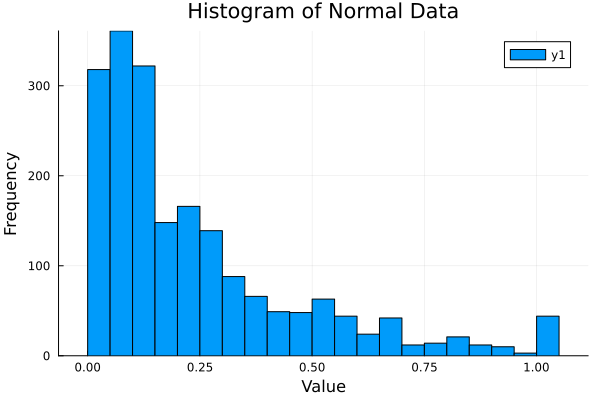

In [141]:
Pkg.add("Plots")
using Plots
outputs = data[:, end]
histogram(outputs, 
    title="Histogram of Normal Data",
    xlabel="Value",
    ylabel="Frequency"
)


In [143]:
edges = [0.25, 0.5, 0.75, 1.0, 6.0]
binned_vector = bin_to_multiclass(outputs, edges)

println("Original Data: ", outputs)
println("Bin Edges: ", edges)
println("Binned Vector (Bin Indices): ", binned_vector)

Original Data: [0.2, 0.67, 0.43, 0.12, 0.03, 0.14, 0.03, 0.55, 0.53, 0.15, 0.24, 0.08, 0.06, 0.09, 0.21, 0.3, 0.49, 0.07, 0.15, 0.03, 0.34, 0.69, 0.21, 0.63, 0.31, 0.12, 0.84, 0.1, 0.49, 0.02, 0.16, 0.19, 0.15, 0.31, 0.08, 0.24, 0.11, 0.22, 0.13, 0.07, 0.11, 0.06, 0.8, 0.22, 0.17, 0.16, 0.2, 0.12, 0.11, 0.12, 0.2, 0.68, 0.23, 0.05, 0.1, 0.28, 0.22, 0.22, 0.55, 0.05, 0.03, 0.07, 0.07, 0.57, 0.37, 0.14, 0.61, 0.03, 0.5, 0.05, 0.04, 0.21, 0.05, 0.02, 0.14, 0.18, 0.12, 0.68, 0.7, 0.75, 0.3, 0.24, 1.0, 0.0, 0.03, 0.06, 0.08, 0.1, 0.27, 0.15, 0.63, 0.05, 0.03, 0.12, 0.4, 0.37, 0.45, 0.04, 0.09, 0.09, 0.39, 0.02, 0.34, 0.28, 0.08, 0.44, 0.24, 0.09, 0.26, 0.4, 0.56, 0.05, 0.06, 0.2, 0.51, 0.04, 0.86, 0.05, 0.06, 0.68, 0.22, 0.05, 0.03, 0.09, 0.17, 0.17, 0.17, 0.14, 0.62, 0.03, 0.23, 0.15, 0.13, 0.27, 0.08, 0.06, 0.09, 0.16, 0.38, 0.02, 0.08, 0.09, 0.3, 0.05, 0.17, 0.53, 1.0, 0.05, 0.63, 1.0, 0.21, 0.86, 0.03, 0.26, 0.87, 0.44, 0.03, 0.73, 0.48, 0.06, 0.07, 0.03, 0.17, 0.11, 0.05, 0.25, 0.05, 0

In [ ]:
LogisticClassifier = @load LogisticClassifier pkg=MLJLinearModels verbosity=0
GaussianNBClassifier = @load GaussianNBClassifier pkg=NaiveBayes verbosity=0

classifiers = Dict(
    "SVM" => createModel(:SVM, {:kernel=>LIBSVM.Kernel.Linear, :C=>1.0, :gamma=>0.1}),
    "DecisionTree" => createModel(:DecisionTreeClassifier, {:max_depth=>5}),
    "KNN" => createModel(:KNeighborsClassifier, {:n_neighbors=>5}),
    "ANN" => createModel(:ANN, {:n_hidden_layers=>1, :n_neurons_per_layer=>10, :activation=>:relu}),
    "NB"  => GaussianNBClassifier(),
    "LogisticRegression" => LogisticClassifier()
)